# Visualizing the History of Nobel Prize Winners

![Nobel Prize medal](Nobel_Prize.png)

This notebook explores all the Nobel Prize winners from 1901 to 2023 with pandas and seaborn. It started as a DataCamp project with six questions about gender, birth country and repeat winners. I extended it by charting the trend behind each answer, and by looking at two questions of my own: how old the winners are, and how often a prize is shared.

**A note on AI use:** The code, the analysis, and the conclusions are my own work. I used AI (Claude) as a writing aid, to help me phrase my findings clearly and to tidy the notebook's formatting and comments.

## Context

The Nobel Prize has been among the most prestigious international awards since 1901. Each year, prizes are given in chemistry, literature, physics, physiology or medicine, economics (since 1969) and peace. Besides the honour and the prize money, each winner gets a gold medal with an image of Alfred Nobel (1833–1896), who created the prize.

The Nobel Foundation shares a dataset of all the winners from 1901 to 2023, taken from the Nobel Prize API. It is stored in `data/nobel.csv`. Each row is one prize given to one laureate. The columns I use are:

| Column | Description |
| --- | --- |
| `year` | Year of the prize |
| `category` | Chemistry, Economics, Literature, Medicine, Peace or Physics |
| `prize_share` | Part of the prize the laureate received (`1/1`, `1/2`, `1/3` or `1/4`) |
| `laureate_type` | `Individual` or `Organization` |
| `full_name` | Name of the laureate |
| `birth_date` | Date of birth |
| `birth_country` | Country of birth |
| `sex` | `Male` or `Female` (empty for organisations) |

The other columns (motivation, organisation and death information) are not used here.

## Goal

Who wins the Nobel Prize, and has the profile of the laureates changed in more than 120 years? I answer seven questions:

1. Which gender and which birth country win the most? 
2. In which decade were US-born winners the largest share of all winners? 
3. In which decade and category were women the largest share of the winners? 
4. Who was the first woman to win, and in what category?
5. Who won more than once? 
6. How old are the laureates when they win, and has it changed?
7. How often is a prize shared, and in which categories?

## Plan

1. Setup
2. Load and inspect the data
3. Explore the data
4. Gender and birth country
5. US-born winners by decade
6. Women by decade and category
7. The first woman
8. Repeat winners
9. Age at the award
10. Shared prizes
11. Conclusion

## 1. Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = "data/nobel.csv"  # path to the data file
BLUE = "#2a78d6"  # main colour of the figures
ORANGE = "#eb6834"  # colour used to highlight

sns.set_style("whitegrid")  # light grid behind every plot

## 2. Load and inspect the data

In [2]:
nobel_df = pd.read_csv(DATA_PATH)
nobel_df.head()

,year,category,prize,motivation,prize_share,laureate_id,laureate_type,full_name,birth_date,birth_city,birth_country,sex,organization_name,organization_city,organization_country,death_date,death_city,death_country
0,1901,Chemistry,The Nobel Prize in Chemistry 1901,"""in recognition of the extraordinary services ...",1/1,160,Individual,Jacobus Henricus van 't Hoff,1852-08-30,Rotterdam,Netherlands,Male,Berlin University,Berlin,Germany,1911-03-01,Berlin,Germany
1,1901,Literature,The Nobel Prize in Literature 1901,"""in special recognition of his poetic composit...",1/1,569,Individual,Sully Prudhomme,1839-03-16,Paris,France,Male,NaN,NaN,NaN,1907-09-07,Châtenay,France
2,1901,Medicine,The Nobel Prize in Physiology or Medicine 1901,"""for his work on serum therapy, especially its...",1/1,293,Individual,Emil Adolf von Behring,1854-03-15,Hansdorf (Lawice),Prussia (Poland),Male,Marburg University,Marburg,Germany,1917-03-31,Marburg,Germany
3,1901,Peace,The Nobel Peace Prize 1901,NaN,1/2,462,Individual,Jean Henry Dunant,1828-05-08,Geneva,Switzerland,Male,NaN,NaN,NaN,1910-10-30,Heiden,Switzerland
4,1901,Peace,The Nobel Peace Prize 1901,NaN,1/2,463,Individual,Frédéric Passy,1822-05-20,Paris,France,Male,NaN,NaN,NaN,1912-06-12,Paris,France


In [3]:
nobel_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   year                  1000 non-null   int64
 1   category              1000 non-null   str  
 2   prize                 1000 non-null   str  
 3   motivation            912 non-null    str  
 4   prize_share           1000 non-null   str  
 5   laureate_id           1000 non-null   int64
 6   laureate_type         1000 non-null   str  
 7   full_name             1000 non-null   str  
 8   birth_date            968 non-null    str  
 9   birth_city            964 non-null    str  
 10  birth_country         969 non-null    str  
 11  sex                   970 non-null    str  
 12  organization_name     736 non-null    str  
 13  organization_city     735 non-null    str  
 14  organization_country  735 non-null    str  
 15  death_date            596 non-null    str  
 16  death_city        

In [4]:
duplicated_rows = nobel_df.duplicated().sum()
missing_values = nobel_df.isnull().sum()

print("Duplicated rows:", duplicated_rows)
print("Missing values:\n", missing_values)
print()
print(nobel_df["laureate_type"].value_counts())

Duplicated rows: 0
Missing values:
 year                      0
category                  0
prize                     0
motivation               88
prize_share               0
laureate_id               0
laureate_type             0
full_name                 0
birth_date               32
birth_city               36
birth_country            31
sex                      30
organization_name       264
organization_city       265
organization_country    265
death_date              404
death_city              421
death_country           415
dtype: int64

laureate_type
Individual      966
Organization     34
Name: count, dtype: int64


The dataset has 1,000 prizes and 18 columns, with no duplicated rows. 966 prizes went to individuals and 34 to organisations.

What I notice about the missing values:
- `sex` is missing 30 times, I would assume all for organisations, which have no sex.
- `birth_date` and `birth_country` are missing about 30 times, mostly for the same organisations.
- The organisation and death columns have many missing values (about 265 and 410), because many laureates are still alive. I do not use these columns anyway.

I do not drop any row because  each question only uses the columns it needs.

The organisations with a value in `sex` look strange, so I check them

In [5]:
wrong_type = (nobel_df["laureate_type"] == "Organization") & (nobel_df["sex"].notna())  # organisations that have a sex

print("Wrongly classified laureates:\n", nobel_df[wrong_type][["year", "category", "full_name", "sex"]])


Wrongly classified laureates:
      year category                            full_name     sex
435  1973    Peace                           Le Duc Tho    Male
501  1979    Peace                        Mother Teresa  Female
598  1989    Peace  The 14th Dalai Lama (Tenzin Gyatso)    Male
618  1991    Peace                     Aung San Suu Kyi  Female


These four are people (for example Mother Teresa and Aung San Suu Kyi), so `laureate_type` is wrong for them. Their `sex` is correct, so they are counted normally in the gender questions. I correct their type to avoid any mistake later on.

In [6]:
nobel_df.loc[wrong_type, "laureate_type"] = "Individual"  # correct their type

print(nobel_df["laureate_type"].value_counts())


laureate_type
Individual      970
Organization     30
Name: count, dtype: int64


So out of the 1,000 prizes, 970 prizes went to individuals and 30 to organizations

## 3. Explore the data

Before answering the questions, I look at how many prizes are given in each decade and in each category. Several questions are about decades, so I create a `decade` column: `year // 10` removes the last digit (1987 → 198), and `* 10` puts back a zero (198 → 1980).

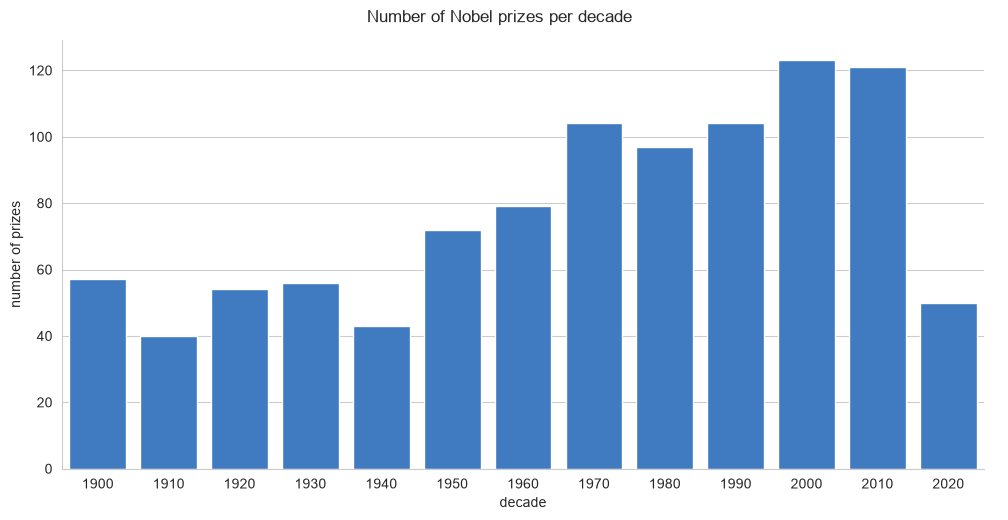

In [7]:
nobel_df["decade"] = (nobel_df["year"] // 10) * 10  # 1987 becomes 1980

g = sns.catplot(x="decade", data=nobel_df, kind="count", color=BLUE, aspect=2)  # one bar per decade
g.set(xlabel="decade", ylabel="number of prizes")
g.figure.suptitle("Number of Nobel prizes per decade", y=1.03)
plt.show()

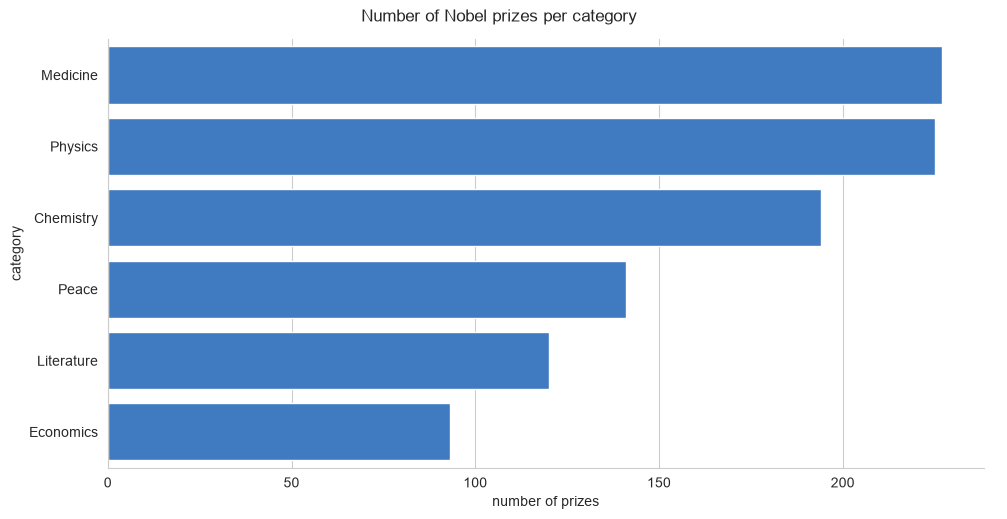

In [8]:
category_order = nobel_df["category"].value_counts().index  # categories from the most to the least prizes

g = sns.catplot(y="category", data=nobel_df, kind="count", color=BLUE, order=category_order, aspect=2)
g.set(xlabel="number of prizes", ylabel="category")
g.figure.suptitle("Number of Nobel prizes per category", y=1.03)
plt.show()

What I notice here:

- The number of prizes per decade doubles over time, from 57 in the 1900s to 123 in the 2000s. There are more prizes because they are shared between more people (see section 10), and because economics was added in 1969.
- The 2020s only contain four years (2020 to 2023), so this decade has fewer prizes (50) and its results rest on fewer laureates.
- Medicine (227) and physics (225) have the most prizes, and economics the fewest (93), since it started 68 years after the others.

## 4. Gender and birth country

In [9]:
top_gender = nobel_df["sex"].value_counts().idxmax()
print(f'Top gender: {top_gender} \n')

top_country = nobel_df["birth_country"].value_counts().idxmax()
print(f'Top country: {top_country} \n')

print(nobel_df["sex"].value_counts())

Top gender: Male 

Top country: United States of America 

sex
Male      905
Female     65
Name: count, dtype: int64


The most common gender is **male**: 905 prizes went to men and 65 to women, so women received less than 7% of the prizes given to people.

To see how far ahead the top country is, I plot the ten most common birth countries.

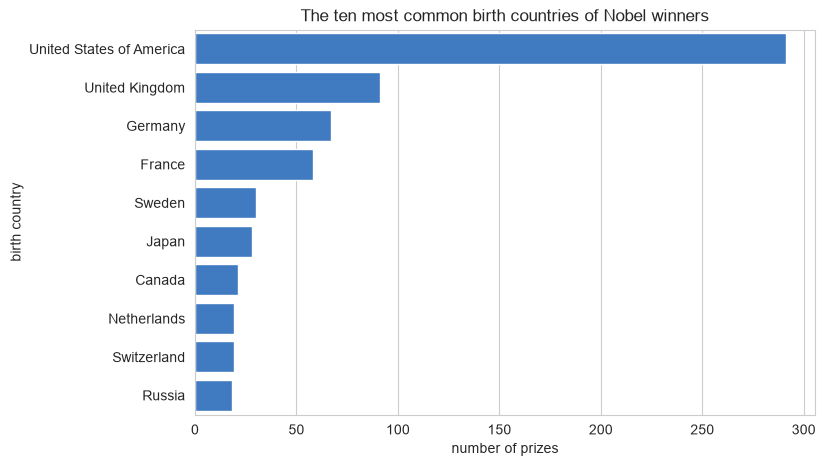

In [10]:
top_countries = nobel_df["birth_country"].value_counts().head(10)  # the ten countries with the most winners

plt.figure(figsize=(8, 5))
sns.barplot(x=top_countries.values, y=top_countries.index, color=BLUE)
plt.title("The ten most common birth countries of Nobel winners")
plt.xlabel("number of prizes")
plt.ylabel("birth country")
plt.show()

The **United States** comes first with 291 prizes, more than the United Kingdom (91), Germany (67) and France (58) together. The top ten is mostly European and North American, with Japan as the only Asian country.

## 5. US-born winners by decade

I look for the decade with the highest **ratio** of US-born winners, not the highest count. I create a `True`/`False` column for US-born winners. The mean of a `True`/`False` column is the share of `True`, so `.mean()` per decade gives the ratio.

In [11]:
nobel_df["us_winner"] = nobel_df["birth_country"] == "United States of America"  # True if born in the US

decade_usa = nobel_df.groupby("decade", as_index=False)["us_winner"].mean()  # share of US-born winners in each decade
max_decade_usa = int(decade_usa.loc[decade_usa["us_winner"].idxmax(), "decade"])  # the decade with the highest share

print("Decade with the highest ratio of US-born winners:", max_decade_usa)
decade_usa.round(3)

Decade with the highest ratio of US-born winners: 2000


,decade,us_winner
0,1900,0.018
1,1910,0.075
2,1920,0.074
3,1930,0.250
4,1940,0.302
5,1950,0.292
6,1960,0.266
7,1970,0.317
8,1980,0.320
9,1990,0.404


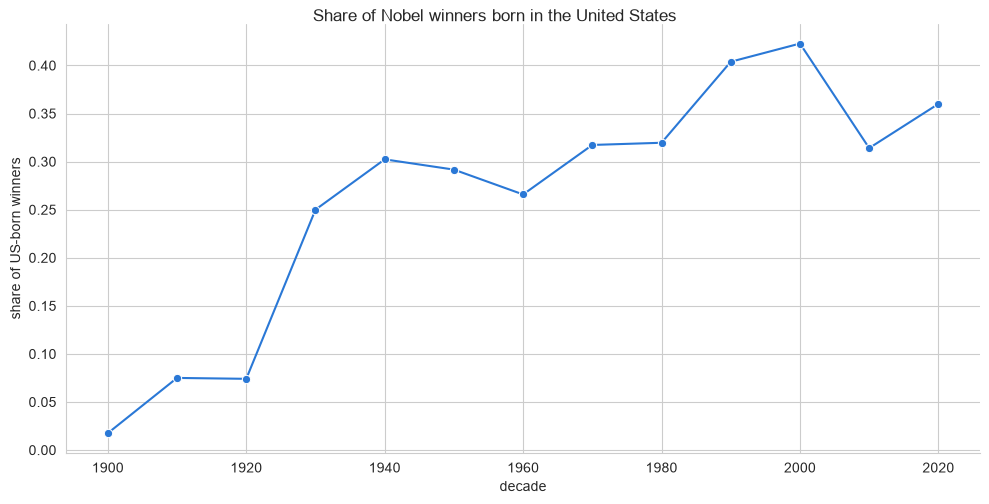

In [12]:
g = sns.relplot(x="decade", y="us_winner", data=decade_usa, kind="line", marker="o", color=BLUE, aspect=2)
g.set(xlabel="decade", ylabel="share of US-born winners")
g.figure.suptitle("Share of Nobel winners born in the United States", y=1)
plt.show()

- The **2000s** have the highest share of US-born winners: 42.3%, so the answer to the question `max_decade_usa` is 2000.

## 6. Women by decade and category

First, I look at the share of women among all winners in each decade, with the same `True`/`False` technique.

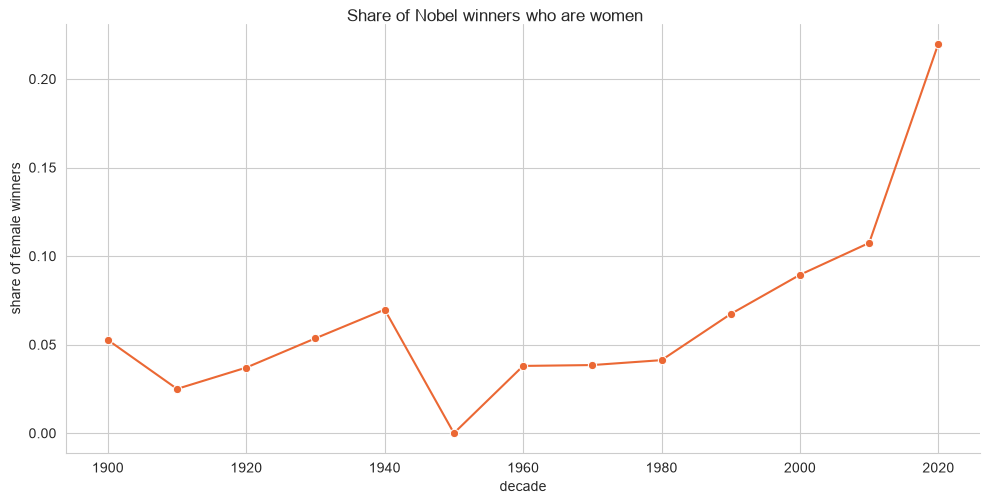

In [13]:
nobel_df["is_female"] = nobel_df["sex"] == "Female"  # True if the laureate is a woman

decade_female_all = nobel_df.groupby("decade", as_index=False)["is_female"].mean()  # share of women in each decade

g = sns.relplot(x="decade", y="is_female", data=decade_female_all, kind="line", marker="o", color=ORANGE, aspect=2)
g.set(xlabel="decade", ylabel="share of female winners")
g.figure.suptitle("Share of Nobel winners who are women", y=1)
plt.show()

For most of the history, women are fewer than 1 winner in 10, the share stays between 0% (1950s) and 7% until the 1990s. It then grows to 8.9% in the 2000s, 10.7% in the 2010s and 22% in the 2020s.

To find the decade **and** category with the highest share, I split by category.

In [14]:
# Calculate the ratio of female winners per decade and category
decade_female = nobel_df.groupby(["decade", "category"], as_index=False)["is_female"].mean()

# Find the row with the maximum ratio
max_idx = decade_female["is_female"].idxmax()
max_female_row = decade_female.loc[max_idx]

# Create a dictionary with decade as key and category as value
max_female_dict = {int(max_female_row["decade"]): max_female_row["category"]}

num_prizes = len(nobel_df[(nobel_df["decade"] == 2020) & (nobel_df["category"] == "Literature")])

print("Dictionary of decades with the highest share of female winners:", max_female_dict)
print("Share of women:", max_female_row["is_female"])
print("Number of prizes in this decade and category:", num_prizes)

Dictionary of decades with the highest share of female winners: {2020: 'Literature'}
Share of women: 0.5
Number of prizes in this decade and category: 4


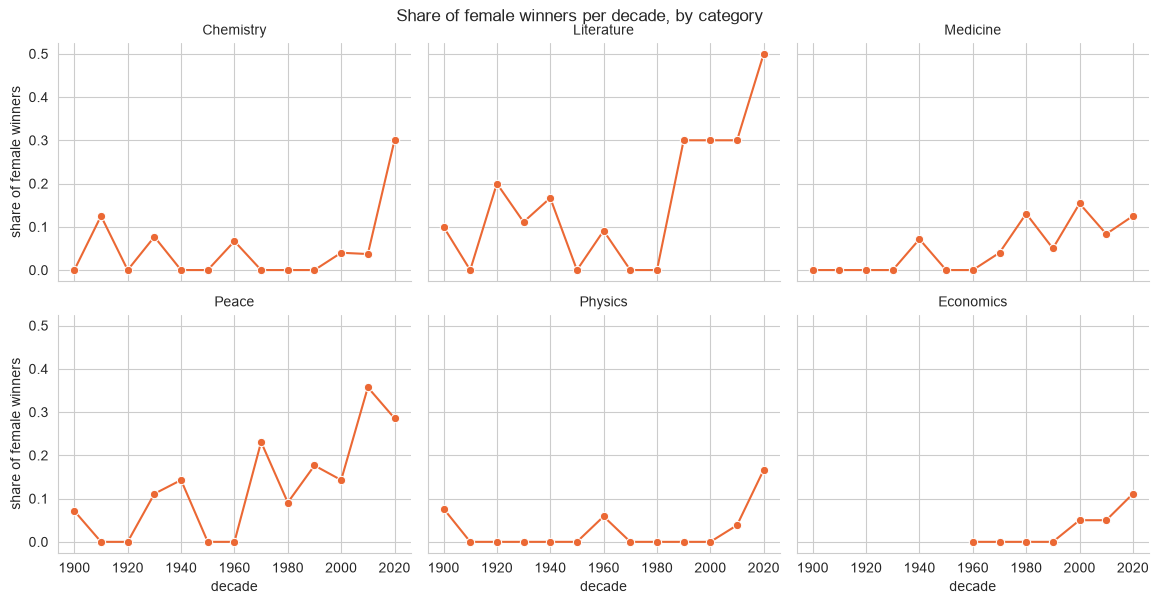

In [15]:
g = sns.relplot(x="decade", 
                y="is_female", 
                data=decade_female, 
                kind="line", 
                marker="o", 
                color=ORANGE,
                col="category", 
                col_wrap=3, 
                height=3, 
                aspect=1.3
                )  # one small plot per category

g.set_titles("{col_name}")  # each small plot is titled with its category
g.set(xlabel="decade", ylabel="share of female winners")
g.figure.suptitle("Share of female winners per decade, by category", y=1)
plt.show()

- The highest share is **literature in the 2020s**: 50% of the winners are women, so `max_female_dict` is `{2020: 'Literature'}`.
- This answer rests on very few prizes: there were only 4 literature prizes from 2020 to 2023, and 2 went to women. One more or one fewer woman would change the share a lot.
- Literature, peace and medicine are the categories where women appear most often. In physics, chemistry and economics, the share stays near 0 for most decades and only starts to rise recently.

## 7. The first woman

I keep only the female winners, sort them by year, and take the first row.

In [16]:
first_woman = nobel_df[nobel_df["is_female"]].sort_values("year").iloc[[0]]  # the earliest prize won by a woman
first_woman_name = first_woman["full_name"].iloc[0]
first_woman_category = first_woman["category"].iloc[0]
first_woman_year = first_woman["year"].iloc[0]

print("First woman:", first_woman_name)
print("Category:", first_woman_category)
print("Year:", first_woman_year)

First woman: Marie Curie, née Sklodowska
Category: Physics
Year: 1903


The first woman to receive a Nobel Prize is **Marie Curie**, in **physics** in 1903. She won again in 1911, in chemistry (see the next section).

## 8. Repeat winners

A laureate who won more than once appears more than once in `full_name`. I count the names and keep those that appear more than once.

In [17]:
repeat_win = nobel_df["full_name"].value_counts()  # number of prizes for each laureate
repeat_winners = repeat_win[repeat_win > 1].index  # names that appear more than once
repeat_list = list(repeat_winners)

print(repeat_list)

['Comité international de la Croix Rouge (International Committee of the Red Cross)', 'Marie Curie, née Sklodowska', 'Linus Carl Pauling', 'Office of the United Nations High Commissioner for Refugees (UNHCR)', 'John Bardeen', 'Frederick Sanger']


In [18]:
nobel_df[nobel_df["full_name"].isin(repeat_list)][["full_name", "year", "category"]].sort_values(["full_name", "year"])  # all the prizes of the repeat winners

,full_name,year,category
89,Comité international de la Croix Rouge (Intern...,1917,Peace
215,Comité international de la Croix Rouge (Intern...,1944,Peace
348,Comité international de la Croix Rouge (Intern...,1963,Peace
306,Frederick Sanger,1958,Chemistry
505,Frederick Sanger,1980,Chemistry
298,John Bardeen,1956,Physics
424,John Bardeen,1972,Physics
278,Linus Carl Pauling,1954,Chemistry
340,Linus Carl Pauling,1962,Peace
19,"Marie Curie, née Sklodowska",1903,Physics


Six laureates won more than once:
- two organisations, both for peace: the **Red Cross** three times (1917, 1944 and 1963) and the **UN refugee agency (UNHCR)** twice (1954 and 1981),
- four people: **John Bardeen** twice in physics, **Frederick Sanger** twice in chemistry, and **Marie Curie** (physics, then chemistry) and **Linus Pauling** (chemistry, then peace), the only two people to win in two different categories.

## 9. Age at the award

Are Nobel laureates young or old when they win, and has it changed? I compute the age as the year of the prize minus the year of birth.

I take the year from the first four characters of `birth_date`. The age can be off by one year, since the exact birthday is not used, because exact birth date was stored incorrectly for several winners, but only the year is correct.

In [19]:
nobel_df["birth_year"] = nobel_df["birth_date"].str[:4].astype(float)  # first four characters = year of birth
nobel_df["age"] = nobel_df["year"] - nobel_df["birth_year"]  # approximate age at the prize

print(nobel_df["age"].describe().round(1))

count    968.0
mean      60.3
std       12.6
min       17.0
25%       51.0
50%       61.0
75%       69.0
max       97.0
Name: age, dtype: float64


The 32 missing birth dates are:

- the 30 organisations, which have no birth date,
- 2 individuals, Saul Perlmutter and Venkatraman Ramakrishnan, who are missing from the source.


In [20]:
nobel_df.sort_values("age")[["full_name", "year", "category", "age"]].dropna().iloc[[0, -1]]  # the youngest and the oldest laureate

,full_name,year,category,age
885,Malala Yousafzai,2014,Peace,17.0
942,John Goodenough,2019,Chemistry,97.0


The median age at the prize is 61. The youngest laureate is Malala Yousafzai (peace, 2014, at 17) and the oldest is John Goodenough (chemistry, 2019, at 97).

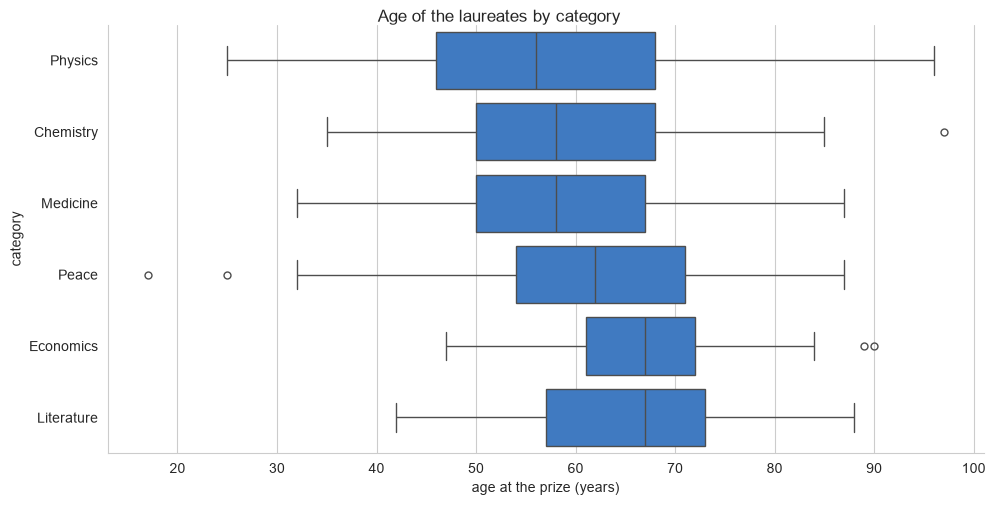

In [21]:
age_order = nobel_df.groupby("category")["age"].median().sort_values().index  # categories from the youngest to the oldest median age

g = sns.catplot(x="age", y="category", data=nobel_df, kind="box", color=BLUE, order=age_order, aspect=2)
g.set(xlabel="age at the prize (years)", ylabel="category")
g.figure.suptitle("Age of the laureates by category", y=1)
plt.show()

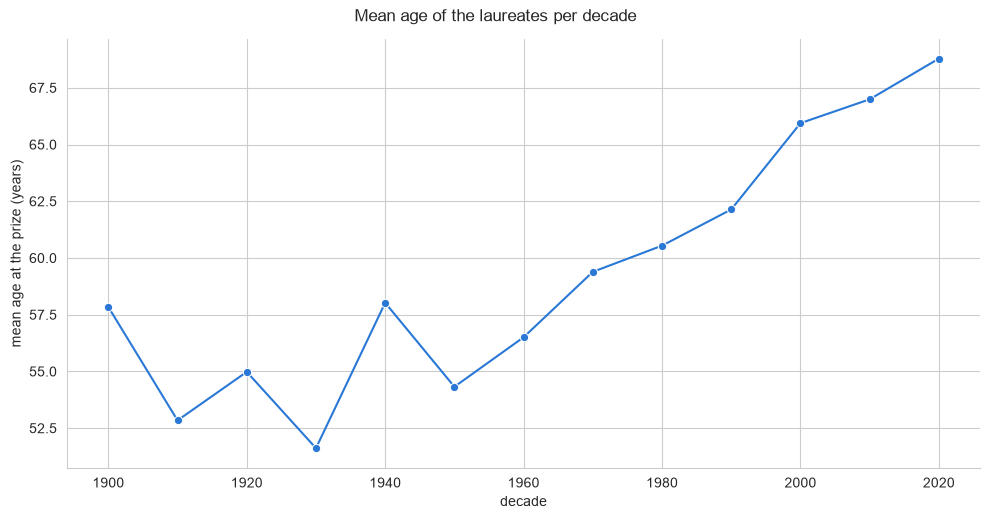

In [22]:
g = sns.relplot(x="decade", y="age", data=nobel_df, kind="line", marker="o", color=BLUE, errorbar=None, aspect=2)  # mean age per decade
g.set(xlabel="decade", ylabel="mean age at the prize (years)")
g.figure.suptitle("Mean age of the laureates per decade", y=1.03)
plt.show()

What I can see:

- Physics winners are the youngest (median 56), followed by chemistry and medicine (58). Literature and economics winners are the oldest (median 67). Peace has the two youngest laureates, at 17 and 25, shown as outliers.
- The mean age stays between 52 and 58 until the 1960s, then rises every decade, up to 68.8 in the 2020s. Laureates now wait much longer for their prize than in the first half of the century.

## 10. Shared prizes

A prize can be split between up to three laureates. `prize_share` is `1/1` when the laureate won alone and `1/2` or `1/3` if the prize was shared. I create a `True`/`False` column for shared prizes and take its mean, like before.

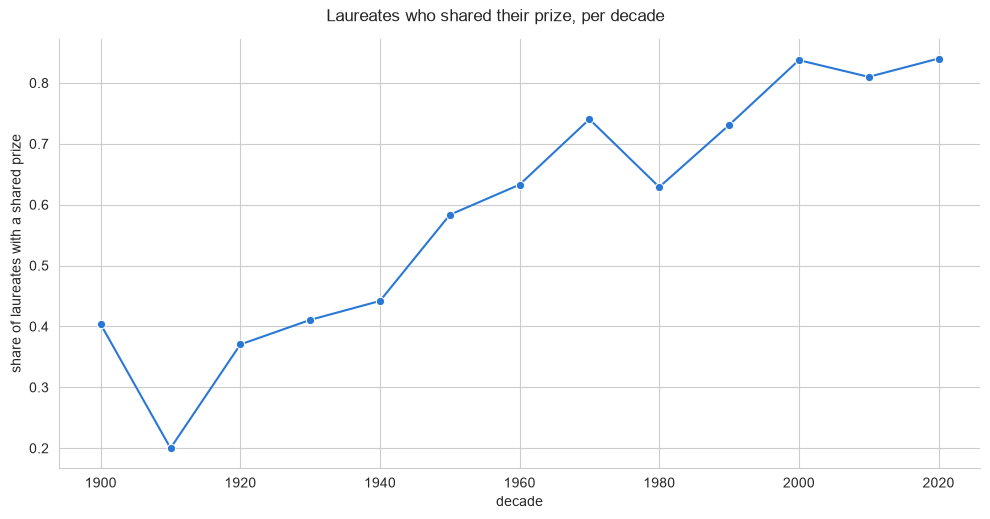

In [23]:
nobel_df["is_shared"] = nobel_df["prize_share"] != "1/1"  # True if the laureate shared the prize

decade_shared = nobel_df.groupby("decade", as_index=False)["is_shared"].mean()  # share of laureates who shared their prize

g = sns.relplot(x="decade", y="is_shared", data=decade_shared, kind="line", marker="o", color=BLUE, aspect=2)
g.set(xlabel="decade", ylabel="share of laureates with a shared prize")
g.figure.suptitle("Laureates who shared their prize, per decade", y=1.03)
plt.show()

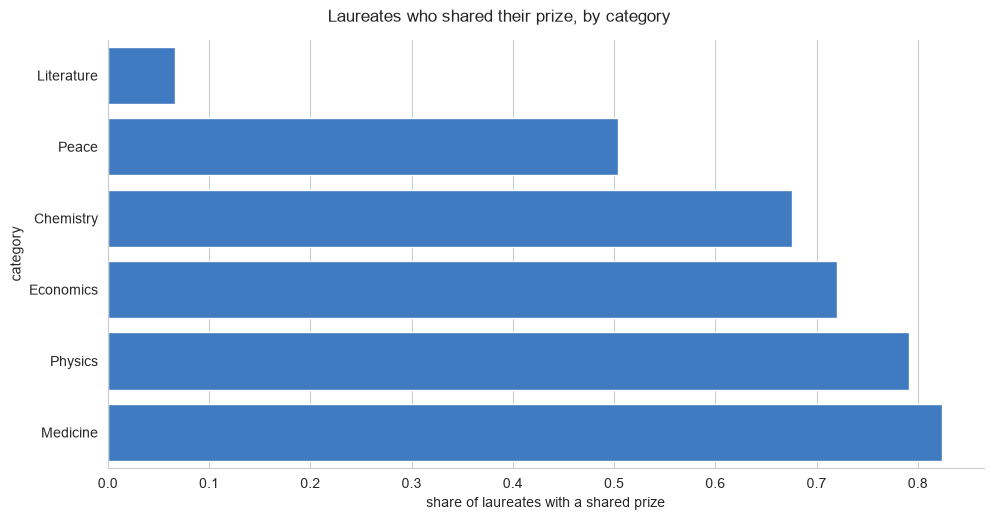

In [24]:
share_order = nobel_df.groupby("category")["is_shared"].mean().sort_values().index

g = sns.catplot(x="is_shared", y="category", data=nobel_df, kind="bar", color=BLUE, errorbar=None, order=share_order, aspect=2) 
g.set(xlabel="share of laureates with a shared prize", ylabel="category")
g.figure.suptitle("Laureates who shared their prize, by category", y=1.03)
plt.show()

- Sharing the prize has become the rule over the years. 40% of the laureates shared their prize in the 1900s, and 84% in the 2000s and 2020s. This explains why there are more prizes per decade (section 3).
- The science categories are shared most often: medicine (82%), physics (79%), economics (72%) and chemistry (68%). The reason is that research is often done in teams, and the prize can reward several people for the same discovery.
- Literature is almost never shared (7%), since a book usually has one author. Peace is in between (50%)

## 11. Conclusion

The table below gathers the answers to the first questions needed to validate the Datacamp verification system.

In [25]:
answers = pd.DataFrame({
    "Question": [
        "Most awarded gender", "Most common birth country", "Decade with the highest US-born ratio",
        "Decade and category with the highest female ratio", "First woman (category)", "Repeat winners",
    ],
    "Variable": ["top_gender", "top_country", "max_decade_usa", "max_female_dict", "first_woman_name", "repeat_list"],
    "Answer": [
        top_gender, top_country, max_decade_usa, max_female_dict,
        f"{first_woman_name} ({first_woman_category})", f"{len(repeat_list)} laureates",
    ],
})
answers

,Question,Variable,Answer
0,Most awarded gender,top_gender,Male
1,Most common birth country,top_country,United States of America
2,Decade with the highest US-born ratio,max_decade_usa,2000
3,Decade and category with the highest female ratio,max_female_dict,{2020: 'Literature'}
4,First woman (category),first_woman_name,"Marie Curie, née Sklodowska (Physics)"
5,Repeat winners,repeat_list,6 laureates


**What the results show**

- **Nobel winners are mostly men, and mostly born in the United States.** Women received less than 7% of the prizes given to winners, and the US alone has 291 prizes, more than the next three countries together.
- **The US share rose over the 20th century**, from almost nothing before 1930 to a peak of 42% in the 2000s.
- **The share of women is rising**, from under 10% for most of the century to 22% in the 2020s. The highest share (literature in the 2020s, 50%) rests on only 4 prizes.
- **Marie Curie** was the first woman to win (physics, 1903), and one of only two people to win in two categories. Six laureates won more than once.
- **Laureates are older and share more:** the mean age went from about 55 to 68.8, and 84% of recent laureates share their prize, especially in the sciences.